# 01 · Exploratory data analysis

**Learning objectives**

1. Measure the properties of behavioural data that drive modelling choices: **sparsity**, the **long tail**, the **funnel** and **repeat behaviour**.
2. Spot data-quality problems (bots, duplicates) *before* they silently corrupt a model.
3. Turn each observation into a concrete decision for the next notebook.

> **Principal DS note.** EDA for recommenders is not about pretty charts. Every plot below should end in a sentence that starts with *"therefore we will..."*

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_or_synthesize
from recsys.plotting import set_style, PALETTE, MUTED

set_style()
events, item_categories, SOURCE = load_or_synthesize()
print(f"{len(events):,} events · {events['visitorid'].nunique():,} visitors · {events['itemid'].nunique():,} items")

  USING SYNTHETIC DATA: data/raw/events.csv was not found.
  The numbers below come from a simulator, NOT from RetailRocket.
  Run `make data` (needs a Kaggle API token) to use the real dataset.
71,281 events · 3,000 visitors · 1,500 items


## 1. Data quality: duplicates and missing values

In [2]:
print("exact duplicate rows:", events.duplicated().sum())
print("missing values per column:")
print(events.isna().sum())
print("\ntransactionid is only set for purchases:",
      events.loc[events["event"] != "transaction", "transactionid"].isna().all())

exact duplicate rows: 0
missing values per column:
timestamp            0
visitorid            0
event                0
itemid               0
transactionid    70399
dtype: int64

transactionid is only set for purchases: True


**Therefore:** drop exact duplicates. A missing `transactionid` is expected, not a data problem.

## 2. The funnel

How often does a view turn into an add-to-cart, and a cart into a purchase?

In [3]:
funnel = events["event"].value_counts().reindex(["view", "addtocart", "transaction"])
conv = pd.DataFrame({
    "events": funnel,
    "share of all events": (funnel / funnel.sum()).map("{:.2%}".format),
    "ratio to previous step": (funnel / funnel.shift(1)).map(lambda x: "" if pd.isna(x) else f"{x:.2%}"),
})
conv

,events,share of all events,ratio to previous step
event,,,
view,68116,95.56%,
addtocart,2283,3.20%,3.35%
transaction,882,1.24%,38.63%


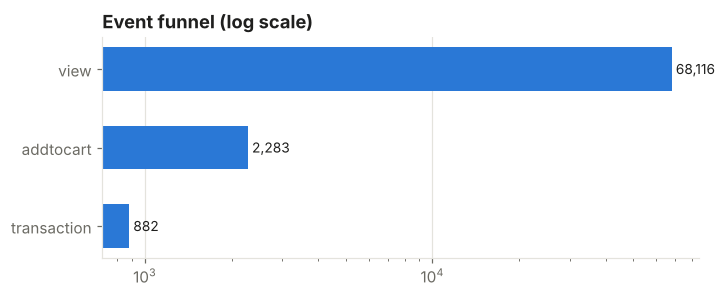

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=PALETTE[0], height=0.55)
for y, v in enumerate(funnel.values[::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_title("Event funnel (log scale)")
ax.grid(axis="y", visible=False)
plt.show()

Views outnumber purchases by two to three orders of magnitude.

**Therefore:**
* Purchases alone are too sparse to train on. We use **all** events, weighted by strength (notebook 02).
* The business cares about purchases, so we should also evaluate on "cart or buy" as well as "any interaction" (notebook 03).

## 3. Users: how much do we know about each one?

In [5]:
per_user = events.groupby("visitorid").agg(n_events=("event", "size"), n_items=("itemid", "nunique"))
print(per_user.describe(percentiles=[0.5, 0.75, 0.9, 0.99, 0.999]).round(1).to_string())
print(f"\nusers with exactly 1 event: {(per_user['n_events'] == 1).mean():.1%}")
print(f"users with ≥ 5 distinct items: {(per_user['n_items'] >= 5).mean():.1%}")

       n_events  n_items
count    3000.0   3000.0
mean       23.8     13.3
std       144.5     77.1
min         1.0      1.0
50%         8.0      5.0
75%        17.0     10.0
90%        32.0     18.0
99%       111.1     47.0
99.9%    2386.1   1205.0
max      2705.0   1261.0

users with exactly 1 event: 6.1%
users with ≥ 5 distinct items: 56.8%


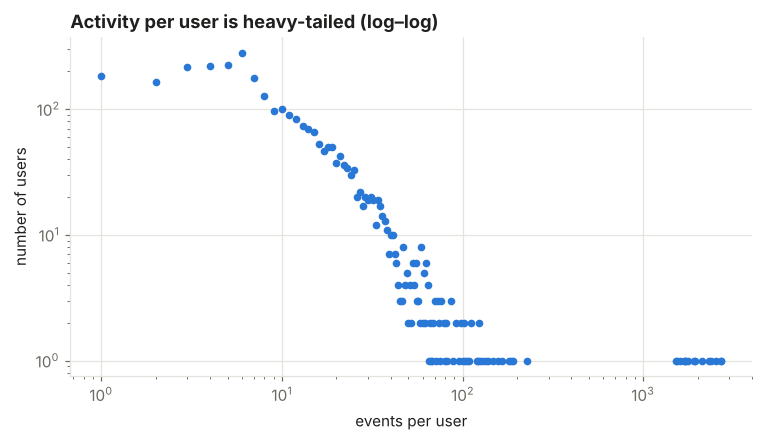

In [6]:
counts = per_user["n_events"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.loglog(counts.index, counts.values, "o", color=PALETTE[0], markersize=4)
ax.set_xlabel("events per user")
ax.set_ylabel("number of users")
ax.set_title("Activity per user is heavy-tailed (log–log)")
plt.show()

On the real data the large majority of visitors have a **single** event. Collaborative filtering cannot personalise for them: one view of one item is not a profile.

**Therefore:**
* Personalised models serve **returning** users. Everyone else gets a non-personalised fallback (popular or trending items).
* We will filter users with too little history out of *training* (k-core, notebook 02). This is a training decision, not a serving one.

## 4. Bots and crawlers

Look at the most active "users".

In [7]:
top = per_user.sort_values("n_events", ascending=False).head(10)
span = events[events["visitorid"].isin(top.index)].groupby("visitorid")["timestamp"].agg(["min", "max"])
top = top.join(span)
top["events_per_day"] = top["n_events"] / ((top["max"] - top["min"]).dt.total_seconds() / 86400).clip(lower=1)
top

,n_events,n_items,min,max,events_per_day
visitorid,,,,,
16799,2705,1256,2015-05-03 00:11:35.826,2015-07-01 23:45:10.165,45.097127
13710,2693,1261,2015-05-03 00:13:05.327,2015-07-01 23:57:42.963,44.891321
7897,2529,1223,2015-05-03 00:28:42.620,2015-07-01 23:57:37.673,42.165169
16500,2386,1205,2015-05-03 00:41:19.343,2015-07-01 23:39:41.076,39.795056
1831,2311,1170,2015-05-03 00:27:38.371,2015-07-01 23:22:34.865,38.545691
18285,2105,1119,2015-05-03 00:01:30.872,2015-07-01 22:54:35.176,35.110531
16230,1940,1079,2015-05-03 00:04:57.406,2015-07-01 23:12:46.559,32.352873
4993,1918,1076,2015-05-03 01:27:07.198,2015-07-01 22:50:24.206,32.024755
15913,1764,1048,2015-05-03 00:18:00.721,2015-07-01 23:59:48.921,29.406193


Thousands of views across thousands of distinct items is not a shopper. Bots are dangerous because they **dominate co-occurrence counts**: one crawler that views every item makes every pair of items look "similar".

**Therefore:** remove users above an activity threshold (`MAX_USER_EVENTS` in `config.py`). The histogram below helps pick it. Look for where the tail stops looking like humans.

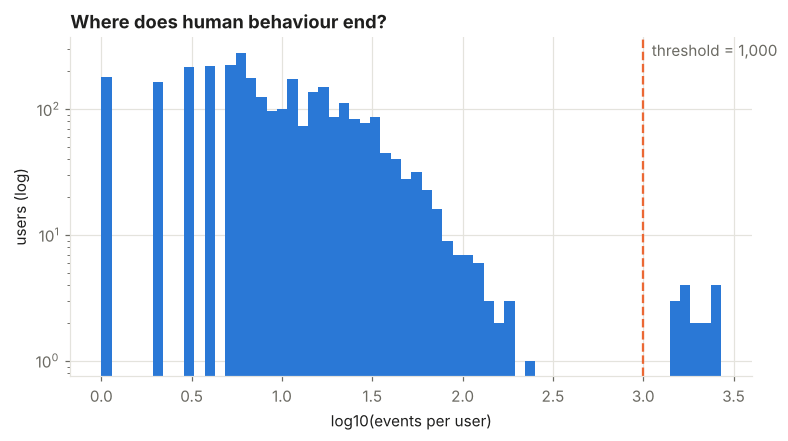

In [8]:
fig, ax = plt.subplots()
ax.hist(np.log10(per_user["n_events"]), bins=60, color=PALETTE[0])
ax.axvline(np.log10(1000), color=PALETTE[1], linestyle="--", linewidth=1.5)
ax.text(np.log10(1000), ax.get_ylim()[1] * 0.9, "  threshold = 1,000", color=MUTED)
ax.set_yscale("log")
ax.set_xlabel("log10(events per user)")
ax.set_ylabel("users (log)")
ax.set_title("Where does human behaviour end?")
plt.show()

## 5. Items: the long tail

top   1% of items (    15) receive 11.3% of user–item interactions
top   5% of items (    75) receive 28.9% of user–item interactions
top  20% of items (   300) receive 53.4% of user–item interactions


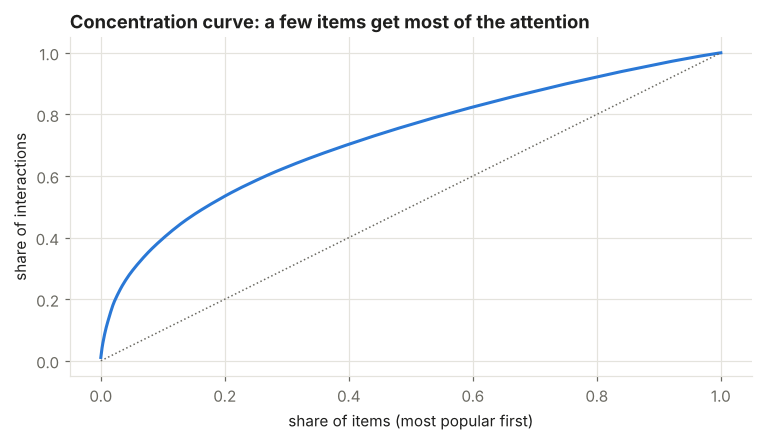

In [9]:
item_users = events.groupby("itemid")["visitorid"].nunique().sort_values(ascending=False)
cum_share = item_users.cumsum() / item_users.sum()
for q in [0.01, 0.05, 0.2]:
    n = int(len(item_users) * q)
    print(f"top {q:>4.0%} of items ({n:>6,}) receive {cum_share.iloc[n - 1]:.1%} of user–item interactions")

fig, ax = plt.subplots()
ax.plot(np.linspace(0, 1, len(cum_share)), cum_share.values, color=PALETTE[0])
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle=":")
ax.set_xlabel("share of items (most popular first)")
ax.set_ylabel("share of interactions")
ax.set_title("Concentration curve: a few items get most of the attention")
plt.show()

**Therefore:**
* A **popularity** baseline will be strong, because most interactions *are* with popular items. We must beat it, not just beat random.
* Models that only learn popularity will have poor **coverage** (most of the catalogue never recommended). We will track coverage and novelty alongside accuracy.

## 6. Sparsity

In [10]:
n_u, n_i = events["visitorid"].nunique(), events["itemid"].nunique()
n_pairs = len(events[["visitorid", "itemid"]].drop_duplicates())
print(f"user × item matrix: {n_u:,} × {n_i:,} = {n_u * n_i:,.0f} cells")
print(f"non-zero cells    : {n_pairs:,}")
print(f"density           : {n_pairs / (n_u * n_i):.6%}")

user × item matrix: 3,000 × 1,500 = 4,500,000 cells
non-zero cells    : 39,853
density           : 0.885622%


Well under 0.01% of the cells are filled on the real data. A dense matrix would not even fit in memory.

**Therefore:** use **sparse matrices** (`scipy.sparse.csr_matrix`) everywhere, and be careful with any operation that densifies them.

## 7. Repeat behaviour

In [11]:
views = events[events["event"] == "view"]
repeat_share = views.duplicated(["visitorid", "itemid"]).mean()
print(f"{repeat_share:.1%} of views are re-views of an item the user already viewed")

41.5% of views are re-views of an item the user already viewed


A lot of behaviour is **re-visiting** items. That is a strong signal of interest, and a strong *predictor* of next week's activity ("you looked at this, come back to it").

**Therefore:** we sum repeated events into one stronger interaction. But we do **not** recommend already-seen items in the carousel, because that is a different product ("recently viewed"). Our evaluation therefore excludes already-seen items from the ground truth.

## 8. Time

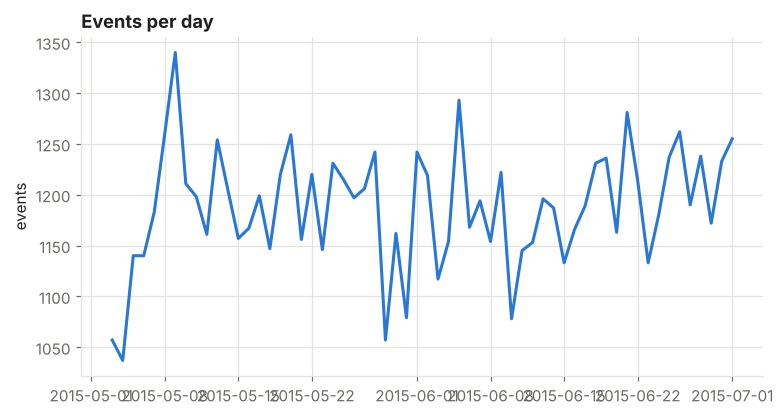

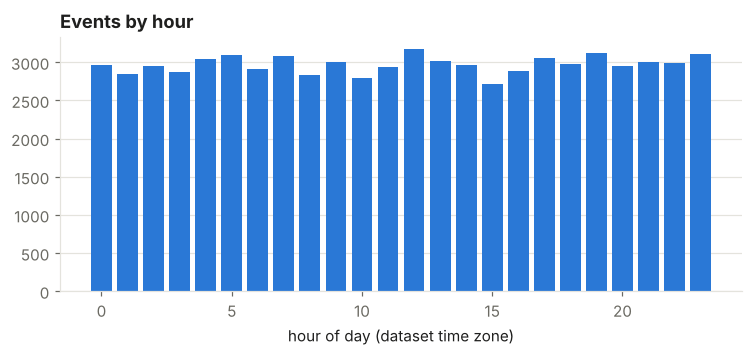

In [12]:
daily = events.set_index("timestamp").resample("D")["event"].size()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color=PALETTE[0])
ax.set_title("Events per day")
ax.set_ylabel("events")
plt.show()

hourly = events["timestamp"].dt.hour.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(hourly.index, hourly.values, color=PALETTE[0], width=0.8)
ax.set_xlabel("hour of day (dataset time zone)")
ax.set_title("Events by hour")
ax.grid(axis="x", visible=False)
plt.show()

Behaviour drifts over time: seasonality, campaigns, new products.

**Therefore:** we must split train and test **by time** (notebook 02). A random split would let the model see the future.

## 9. Categories (if available)

In [13]:
if item_categories is not None:
    ev_cat = events.merge(item_categories, on="itemid", how="left")
    print(f"events with a known category: {ev_cat['categoryid'].notna().mean():.1%}")
    print(f"distinct categories: {ev_cat['categoryid'].nunique():,}")
    print(ev_cat["categoryid"].value_counts().head(10).to_string())
else:
    print("item_properties files not found: category features will be skipped.")

events with a known category: 100.0%
distinct categories: 12
categoryid
11    6376
3     6255
1     6208
0     6193
10    6076
7     6069
6     5878
8     5784
2     5720
5     5717


## Key takeaways

| Observation | Decision |
|---|---|
| Views ≫ carts ≫ purchases | Use all events, weighted by strength |
| Most users have 1 event | Personalise returning users; fall back to trending |
| A few "users" with thousands of events | Remove bots before computing anything |
| Long-tailed item popularity | Popularity is a strong baseline; track coverage |
| Extreme sparsity | Sparse matrices everywhere |
| Many re-views | Sum repeats; exclude seen items from recs and ground truth |
| Drift over time | Temporal train/test split |

## Exercises

1. **(Easy)** What share of purchases happen without a recorded add-to-cart first? What could explain it?
2. **(Medium)** Compute the median time between a user's view of an item and their purchase of it. What does that suggest about the right length for the test window?
3. **(Medium)** Sessionise the log: split each user's events wherever there is a gap of more than 30 minutes. How many sessions does a typical user have?
4. **(Stretch)** Find a better bot heuristic than a single threshold. For example, use events per *minute*, or the share of items viewed only once. How many users does it flag that the threshold misses?